[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/trajectories.ipynb)

# Trajectories of features at orders 1 to 4

This tutorial computes features of orders 1 to 4 with `tc.features` on three real datasets from different domains, reduces each order to three dimensions, and animates the result as a trajectory with [hypertools](https://hypertools.readthedocs.io/). You will see how to compare the shape of a dataset's trajectory across orders.

**Data.**

- *Brain activity during story listening*: the HTFA node weights of 36 people listening to a story (Simony et al., 2016, [doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141)), as analyzed by Owen, Chang & Manning (2021, [doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). The loading code is that of the [HTFA tutorial](htfa_network_animations.ipynb), which describes the data; the archive is 460 MB.
- *Stock market*: the daily log returns of the 49 US industry portfolios of the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), 2005 to 2024, as in the [stock-market tutorial](stocks.ipynb).
- *Human movement*: trial 2 of subject 86 of the [CMU Graphics Lab Motion Capture Database](http://mocap.cs.cmu.edu/) ("walk, squats, run, stretch, jumps, punches, and drinking", [trial list](http://mocap.cs.cmu.edu/search.php?subjectnumber=86)): the joint angles of one person, recorded at 120 frames per second. The data used here were obtained from mocap.cs.cmu.edu; the database was created with funding from NSF EIA-0196217.

Downloads are cached in the folder set by the `TIMECORR_DATA` environment variable (default `~/timecorr_data`). The notebook takes about 2 minutes on a 12-core laptop, most of it rendering the videos, and took 18 minutes on a Colab CPU runtime with 2 cores (before the frames were saved with faster compression); the last cell prints its run time.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.0 or
# later from PyPI, or, when that install fails, the GitHub branch named in FALLBACK.
# bottleneck>=1.5: pandas 3, which the tutorial extras install, warns about the older
# bottleneck that Colab has.
import subprocess
import sys

if "google.colab" in sys.modules:
    PACKAGE = "timecorr[tutorials]"
    OTHERS = ["bottleneck>=1.5"]  # other packages installed with it
    FALLBACK = "master"  # GitHub branch installed when PyPI does not have the release

    def pip_install(requirement):
        # returns pip's exit status and its output
        result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", requirement, *OTHERS],
                                capture_output=True, text=True)
        return result.returncode, result.stdout + result.stderr

    status, pypi_output = pip_install(f"{PACKAGE}>=0.3.0")
    if status == 0:
        print("Installed timecorr from PyPI.")
    else:
        status, github_output = pip_install(
            f"{PACKAGE} @ git+https://github.com/ContextLab/timecorr.git@{FALLBACK}")
        if status:
            print(pypi_output + github_output)
            raise RuntimeError("timecorr could not be installed; see pip's messages above.")
        print(f"Installed timecorr from the {FALLBACK} branch on GitHub (not from PyPI).")

In [2]:
import contextlib
import hashlib
import io
import itertools
import logging
import os
import subprocess
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import hypertools as hyp
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
from IPython.display import HTML, Video, display
from joblib import Parallel, delayed
from mpl_toolkits.mplot3d import proj3d
from PIL import Image as PILImage

import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
DATA_ROOT = Path(os.environ.get('TIMECORR_DATA', Path.home() / 'timecorr_data'))
print('timecorr', tc.__version__, '| hypertools', hyp.__version__)


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def download(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        tmp = path.with_suffix('.part')
        try:
            urllib.request.urlretrieve(url, tmp)
        except OSError as err:
            raise RuntimeError(f'could not download {url} ({err})') from err
        tmp.replace(path)
    return path

timecorr 0.3.0 | hypertools 1.1.0


## 1. Loading the three datasets

**Story listening.** As in the HTFA tutorial: the node weights of the intact condition, the nodes whose weights are never constant, and 100 of them spread over the brain by farthest-point sampling. The result is one matrix (timepoints by nodes) per participant.

In [3]:
fit_path = DATA_ROOT / 'pieman' / 'pieman_posterior_K700.mat'     # shared with the HTFA tutorial
if not fit_path.exists():
    archive = download('https://drive.usercontent.google.com/download'
                       '?id=1CZYe8eyAkZFuLqfwwlKoeijgkjdW6vFs&export=download&confirm=t',
                       DATA_ROOT / 'pieman' / 'data.zip')
    with zipfile.ZipFile(archive) as z, z.open('data/pieman_posterior_K700.mat') as src, \
            open(fit_path, 'wb') as dst:
        while chunk := src.read(1 << 20):
            dst.write(chunk)
    archive.unlink()
if sha256(fit_path) != '870179316f127776ff78096c361df6b1c5c7957d6456deb26b5489bcee6c0793':
    raise RuntimeError(f'{fit_path} does not match its checksum; delete it and run this cell again')

post = scipy.io.loadmat(fit_path)['posterior'][0, 0]
names = [str(n[0]) for n in post['subjects_names'][0]]
centers = np.asarray(post['centers'][0, 0]['mean'], dtype=float)
intact = sorted((i for i, n in enumerate(names) if n.startswith('intact_')),
                key=lambda i: int(names[i].split('_s')[1].split('.')[0]))
weights = np.stack([post['subjects'][0, i]['image_weights'][0, 0]['mean'][0, 0] for i in intact])
del post
usable = np.flatnonzero(~(weights.std(axis=1) < 1e-6).any(axis=0))


def farthest_points(points, k):
    chosen = [int(np.argmin(np.linalg.norm(points - points.mean(axis=0), axis=1)))]
    dist = np.linalg.norm(points - points[chosen[0]], axis=1)
    for _ in range(k - 1):
        chosen.append(int(np.argmax(dist)))
        dist = np.minimum(dist, np.linalg.norm(points - points[chosen[-1]], axis=1))
    return np.array(chosen)


nodes = usable[farthest_points(centers[usable], 100)]
story = [w[:, nodes] for w in weights]
print(f'story listening: {len(story)} participants, each {story[0].shape[0]} timepoints by {story[0].shape[1]} nodes')

story listening: 36 participants, each 300 timepoints by 100 nodes


**Stock market.** As in the stock-market tutorial: the value-weighted daily returns of the 49 industries, 2005 to 2024, as log returns.

In [4]:
zip_path = download('https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
                    '49_Industry_Portfolios_daily_CSV.zip', DATA_ROOT / 'french' / '49_Industry_Portfolios_daily_CSV.zip')
with zipfile.ZipFile(zip_path) as z:
    lines = z.read(z.namelist()[0]).decode('latin-1').splitlines()
first = next(i for i, line in enumerate(lines) if 'Average Value Weighted Returns -- Daily' in line)
last = next(i for i in range(first + 1, len(lines)) if not lines[i].strip())
table = pd.read_csv(io.StringIO('\n'.join(lines[first + 1:last])), index_col=0)
table.index = pd.to_datetime(table.index.astype(str).str.strip(), format='%Y%m%d')
table = table.loc['2005-01-01':'2024-12-31']
table = table.loc[:, (table > -99.99).all()]        # drop industries with missing values
stock_dates = table.index
stocks = np.log1p(table.values / 100)
print(f'stock market: {stocks.shape[0]} trading days by {stocks.shape[1]} industries')

stock market: 5033 trading days by 49 industries


**Human movement.** The motion file (AMC format) lists, for every frame, the angles of each joint in degrees. The cell keeps the joint angles (not the position and orientation of the body as a whole), drops the angles that never change, removes the 360-degree jumps of angles that wrap around, and averages blocks of 10 frames (12 samples per second).

In [5]:
amc = download('http://mocap.cs.cmu.edu/subjects/86/86_02.amc', DATA_ROOT / 'cmu_mocap' / '86_02.amc')
if sha256(amc) != 'c89f384eddeee3bf1baf7311058d36b10fcdd70c900ba8d30197a391e61cd990':
    raise RuntimeError(f'{amc} does not match its checksum; delete it and run this cell again')

frames, current = [], None
for line in amc.read_text().splitlines():
    if line.startswith(('#', ':')):
        continue
    fields = line.split()
    if len(fields) == 1 and fields[0].isdigit():         # a frame number starts a new frame
        current = {}
        frames.append(current)
    elif current is not None:
        current[fields[0]] = [float(v) for v in fields[1:]]
channels = [(joint, i) for joint, values in frames[0].items() if joint != 'root' for i in range(len(values))]
angles = np.array([[f[joint][i] for joint, i in channels] for f in frames])
angles = angles[:, angles.std(axis=0) > 1e-3]          # angles that change
angles = np.unwrap(angles, period=360, axis=0)
n = len(angles) // 10 * 10
movement = angles[:n].reshape(-1, 10, angles.shape[1]).mean(axis=1)
MOVEMENT_RATE = 12                                      # samples per second
print(f'human movement: {len(frames)} frames ({len(frames) / 120:.1f} s) -> '
      f'{movement.shape[0]} samples by {movement.shape[1]} joint angles')

human movement: 10617 frames (88.5 s) -> 1061 samples by 50 joint angles


## 2. Features of orders 1 to 4

For each dataset, `tc.features(data, order=4, return_info=True)` with the defaults. For the story-listening data, the features are computed per participant and then averaged over participants. The cell prints the number of columns of each order's features and the warnings that `tc.features` issues.

The defaults choose each kernel's width from the data, and `return_info` records it. Near the ends of a recording the kernels are cut off, and the features there are far from those in the middle, which would squeeze the rest of a trajectory into a corner of the plot. So the cell leaves out the first and last `edge` timepoints, twice the largest kernel standard deviation (printed).

A warning about a constant `WeightedStrength` column refers to the line `constant:` below it, which names the column. A magnitude column with value 0 belongs to a feature whose pair weights are all in the low group that centering subtracts (`a_ij = max(w_ij - m, 0)` in `tc.WeightedStrength`).

In [6]:
DATASETS = {'Story listening': story, 'Stock market': stocks, 'Human movement': movement}
features, edges = {}, {}
for name, data in DATASETS.items():
    print(f'{name}: computing features ({time.time() - NOTEBOOK_START:.0f} s after the start)', flush=True)
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
        X, info = tc.features(data, order=4, return_info=True)
    # the columns that are constant over time (index [participant] for lists; magnitude columns come first)
    constant = []
    for k in range(1, 5):
        for p, x in enumerate(X[k] if isinstance(X[k], list) else [X[k]]):
            for c in np.flatnonzero(np.ptp(x, axis=0) == 0):
                where = f'X[{k}][{p}]' if isinstance(X[k], list) else f'X[{k}]'
                kind = 'magnitude' if k >= 2 and c < x.shape[1] // 2 else 'column'
                constant.append(f'  constant: {where}[:, {c}] ({kind}), value {x[0, c]:.3g}')
    if isinstance(data, list):
        X = [np.mean(x, axis=0) for x in X]
    # kernel standard deviations in timepoints (rows of each order's input times timepoints per row)
    widest = max(step['kernel_sd'] * step.get('sampling', 1) for step in info)
    edges[name] = edge = int(np.ceil(2 * widest))
    features[name] = [x[edge:len(x) - edge] for x in X]
    widths = ', '.join(f'X[{k}]: {X[k].shape[1]}' for k in range(1, 5))
    print(f'{name}: {time.time() - start:.0f} s; columns {widths}; '
          f'largest kernel sd {widest:.0f} timepoints, edge {edge}')
    for message in sorted({str(w.message) for w in caught}):
        print(f'  warning ({sum(str(w.message) == message for w in caught)}x): {message}')
    for line in constant:
        print(line)

Story listening: computing features (1 s after the start)
Story listening: 25 s; columns X[1]: 100, X[2]: 200, X[3]: 8, X[4]: 8; largest kernel sd 10 timepoints, edge 20
  warning (1x): WeightedStrength: 1 output column is constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.
  constant: X[4][31][:, 3] (magnitude), value 0
Stock market: computing features (25 s after the start)
Stock market: 1 s; columns X[1]: 49, X[2]: 18, X[3]: 18, X[4]: 18; largest kernel sd 50 timepoints, edge 101
Human movement: computing features (27 s after the start)
Human movement: 0 s; columns X[1]: 50, X[2]: 10, X[3]: 10, X[4]: 10; largest kernel sd 11 timepoints, edge 22
  warning (1x): Automatic feeding reducer at order 2: the shift null found no structure (no eigenvalue above null_threshold=0.1865); this order uses WeightedStrength on its 5 input features.
  warning (1x): Automatic feeding redu

## 3. The trajectories

Each panel reduces one order's features to three dimensions with hypertools (its default, incremental PCA, fit separately for each order) and draws them as a line through time. `antialias=False` draws straight segments between the samples, so every vertex of the line is a sample. Rows are datasets, columns are orders.

`trajectory_panel` replaces hypertools' cube, which spans the same range on every axis, with a box fitted to the whole trajectory plus a small margin. The sides of the box are proportional to the trajectory's extent, so its shape is not stretched. `fill_panel` then zooms the box until it fills its panel.

`quiet_hypertools` drops two messages while hypertools draws, and nothing else: a warning, on every `hyp.plot` call in a notebook without `ipympl`, that interactive plots may not appear, and a macOS log line about the weight of one of hypertools' fallback fonts.

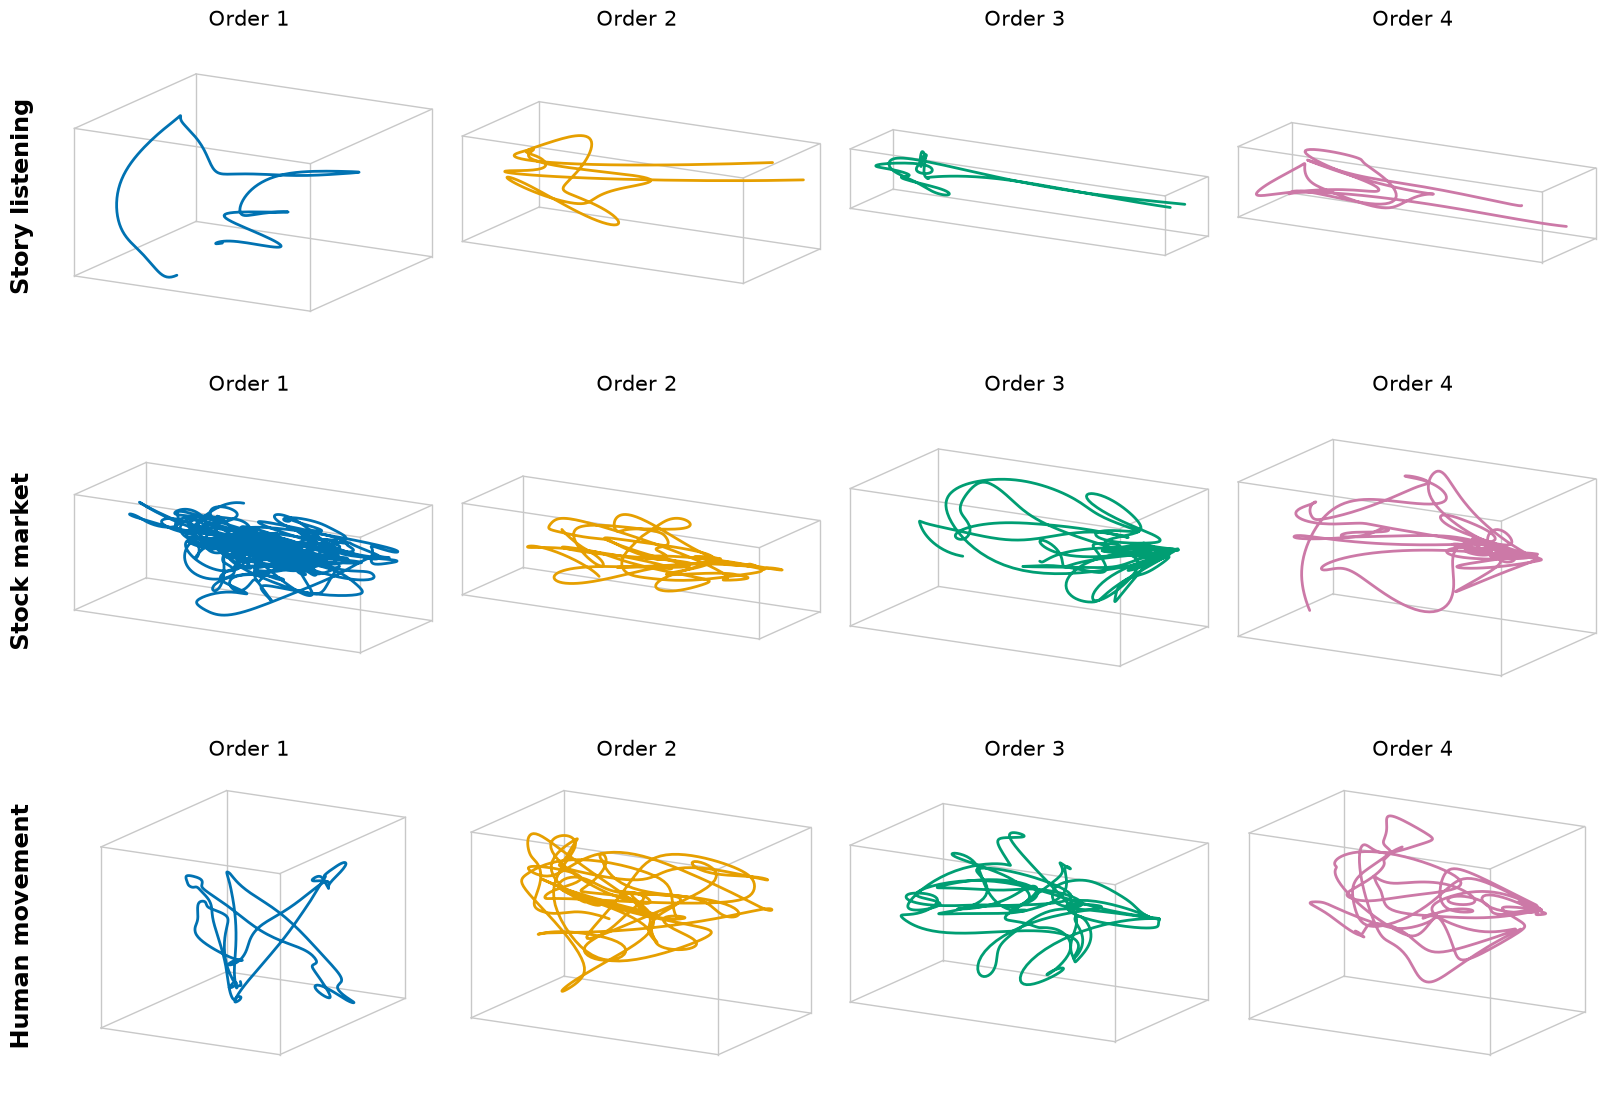

In [7]:
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']          # one color per order
BACKEND_MESSAGE = (r'The `ipympl` package is not installed in the Jupyter server|'
                   r'Failed to switch to interactive notebook backend')
FONT_WEIGHT_MESSAGE = 'findfont: Failed to find font weight normal for Hiragino Kaku Gothic ProN, now using 300.'


@contextlib.contextmanager
def quiet_hypertools():
    def keep(record):
        return record.getMessage() != FONT_WEIGHT_MESSAGE
    font_log = logging.getLogger('matplotlib.font_manager')
    font_log.addFilter(keep)
    try:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message=BACKEND_MESSAGE, category=UserWarning,
                                    module=r'hypertools\.plot\.backend')
            yield
    finally:
        font_log.removeFilter(keep)


def trajectory_panel(ax, x, color, title, linewidth, fontsize, margin=0.04):
    """Draw one order's trajectory with hypertools in a box fitted to it.

    Returns the line hypertools drew and its vertices (one row per sample)."""
    hyp.plot(x, ax=ax, show=False, backend='matplotlib', antialias=False, color=color,
             linewidth=linewidth)
    line = ax.lines[-1]
    points = np.column_stack(line.get_data_3d())
    for artist in list(ax.collections):                     # hypertools' cube
        artist.remove()
    low, high = points.min(axis=0), points.max(axis=0)
    pad = margin * (high - low).max()
    low, high = low - pad, high + pad
    ax.set(xlim=(low[0], high[0]), ylim=(low[1], high[1]), zlim=(low[2], high[2]))
    ax.set_box_aspect(high - low)
    ax.set_proj_type('ortho')
    for a, b in itertools.combinations(itertools.product(*zip(low, high)), 2):
        if np.sum(np.array(a) != np.array(b)) == 1:          # the 12 edges of the box
            ax.plot(*zip(a, b), color='#c8c8c8', linewidth=1, zorder=0)
    ax.set_title(title, fontsize=fontsize)
    return line, points


def fill_panel(ax, azimuths, elev=15, fill=0.94, title_px=60):
    """Zoom the box so that, at every camera angle in azimuths, it fills its panel.

    A 3-D axes draws in a square inside its panel; the box may extend past that square
    (clipping is turned off), but not past the panel."""
    ax.apply_aspect()
    panel = ax.get_position(original=True).transformed(ax.figure.transFigure)
    corners = np.array(list(itertools.product(ax.get_xlim(), ax.get_ylim(), ax.get_zlim())))
    width = height = 0
    for azim in azimuths:
        ax.view_init(elev=elev, azim=azim)
        x, y, _ = proj3d.proj_transform(*corners.T, ax.get_proj())
        pixels = ax.transData.transform(np.column_stack([x, y]))
        width, height = max(width, np.ptp(pixels[:, 0])), max(height, np.ptp(pixels[:, 1]))
    zoom = fill * min(panel.width / width, (panel.height - title_px) / height)
    ax.set_box_aspect(ax.get_box_aspect(), zoom=zoom)
    for artist in ax.lines:
        artist.set_clip_on(False)


with quiet_hypertools():
    fig, axes = plt.subplots(3, 4, figsize=(16, 11), subplot_kw={'projection': '3d'})
    for row, (name, X) in enumerate(features.items()):
        for k in range(1, 5):
            trajectory_panel(axes[row, k - 1], X[k], COLORS[k - 1], f'Order {k}', linewidth=2, fontsize=15)
    fig.subplots_adjust(left=0.035, right=1, bottom=0, top=0.96, wspace=0.02, hspace=0.12)
    for row, name in enumerate(features):
        box = axes[row, 0].get_position()
        fig.text(0.012, (box.y0 + box.y1) / 2, name, rotation=90, ha='center', va='center',
                 fontsize=17, weight='bold')
    for ax in axes.flat:
        fill_panel(ax, [-60], title_px=45)
    display(fig)
    plt.close(fig)

## 4. Animations

One video per dataset, with the four orders side by side. Each frame shows one sample: the line up to that sample, with the last `TAIL` samples drawn thicker. Nothing is drawn between samples, and the frames follow the samples at 30 frames per second; for long recordings, only every `step`-th sample gets a frame (the step is given for each video). The last frame is held for one second, and the camera turns slowly.

hypertools' own animations (`hyp.plot(..., animate=True)`) interpolate between samples, so the notebook drives the frames itself. Each worker draws the four panels once with `trajectory_panel` (that is, with `hyp.plot`), and each frame then cuts the line hypertools drew back to the samples up to the current one. Frames are drawn in parallel (up to three workers) and encoded to H.264 (1920 x 1080) with the ffmpeg of `imageio-ffmpeg`. In the documentation the videos are linked files; elsewhere (for example on Colab) they are saved in `tutorial_media/` and shown inline.

In [8]:
# Inside the documentation sources (docs/tutorial), videos go to docs/_static/tutorial_media and
# are linked; anywhere else (for example on Colab), they go to ./tutorial_media and are embedded.
IN_DOCS = (Path('..') / 'conf.py').exists() and (Path('..') / '_static').is_dir()
MEDIA_DIR = Path('..') / '_static' / 'tutorial_media' if IN_DOCS else Path('tutorial_media')
MEDIA_DIR.mkdir(parents=True, exist_ok=True)
CORES = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count() or 1  # usable cores
N_JOBS = min(3, CORES)                                      # parallel frame-drawing workers


def show_video(path):
    if IN_DOCS:
        src = Path(os.path.relpath(path)).as_posix()
        display(HTML(f'<video src="{src}" controls loop muted playsinline preload="metadata" '
                     f'style="width: 100%; max-width: 960px;"></video>'))
    else:
        display(Video(str(path), embed=True, width=960,
                      html_attributes='controls loop muted playsinline'))


FPS, CRF = 30, 23
TAIL = 30                                                    # samples drawn thicker
DEGREES_PER_FRAME = 0.25                                     # camera turn


def render_chunk(X, title, captions, samples, frame_ids, folder):
    with quiet_hypertools():                                 # in each worker process
        fig, axes = plt.subplots(2, 2, figsize=(19.2, 10.8), dpi=100, facecolor='white',
                                 subplot_kw={'projection': '3d'})
        panels = []
        for k, ax in enumerate(axes.flat, start=1):
            line, points = trajectory_panel(ax, X[k], COLORS[k - 1], f'Order {k}', linewidth=2.5,
                                            fontsize=24)
            panels.append((ax, line, points))
        fig.subplots_adjust(left=0, right=1, bottom=0, top=0.85, wspace=0.02, hspace=0.12)
        fig.text(0.015, 0.975, title, fontsize=30, va='top', weight='bold')
        caption = fig.text(0.985, 0.975, '', fontsize=26, va='top', ha='right', color='#444444')
        last = len(samples) - 1
        azimuths = -60 + DEGREES_PER_FRAME * np.linspace(0, last, 13)
        drawn = []
        for k, (ax, line, points) in enumerate(panels, start=1):
            line.set_alpha(0.45)
            tail, = ax.plot([], [], [], color=COLORS[k - 1], linewidth=5, solid_capstyle='round')
            head, = ax.plot([], [], [], 'o', color=COLORS[k - 1], markersize=11,
                            markeredgecolor='white', markeredgewidth=1.5)
            fill_panel(ax, azimuths, title_px=50)
            drawn.append((ax, line, tail, head, points))
        for i in frame_ids:
            s = samples[min(i, last)]                        # frames past the end hold the last sample
            for ax, line, tail, head, points in drawn:
                line.set_data_3d(*points[:s + 1].T)
                tail.set_data_3d(*points[max(0, s - TAIL):s + 1].T)
                head.set_data_3d(*points[s:s + 1].T)
                ax.view_init(elev=15, azim=-60 + DEGREES_PER_FRAME * min(i, last))
            caption.set_text(captions(s))
            fig.canvas.draw()
            frame = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])
            frame.save(folder / f'{i:05d}.png', compress_level=1)     # read once by ffmpeg
        plt.close(fig)


def render(name, step, captions):
    X = features[name]
    T = len(X[1])
    samples = np.arange(0, T, step)
    if samples[-1] != T - 1:
        samples = np.append(samples, T - 1)                 # always end on the last sample
    n_frames = len(samples) + FPS                           # plus one second on the last sample
    folder = DATA_ROOT / 'frames' / name.replace(' ', '_').lower()
    folder.mkdir(parents=True, exist_ok=True)
    for old in folder.glob('*.png'):
        old.unlink()
    print(f'{name}: drawing {n_frames} frames with {N_JOBS} worker(s)', flush=True)
    start = time.time()
    Parallel(n_jobs=N_JOBS)(delayed(render_chunk)(X, f'{name}: features of orders 1 to 4', captions,
                                             samples, chunk, folder)
                       for chunk in np.array_split(np.arange(n_frames), 12))
    path = MEDIA_DIR / f'trajectories_{name.replace(" ", "_").lower()}.mp4'
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-y', '-loglevel', 'error', '-framerate', str(FPS),
                    '-i', str(folder / '%05d.png'), '-c:v', 'libx264', '-preset', 'slow', '-crf', str(CRF),
                    '-pix_fmt', 'yuv420p', '-movflags', '+faststart', str(path)], check=True)
    print(f'{len(samples)} samples (every {step}) -> {n_frames} frames ({n_frames / FPS:.1f} s) '
          f'in {time.time() - start:.0f} s; {path.name}: {path.stat().st_size / 1e6:.1f} MB')
    for frame in folder.glob('*.png'):
        frame.unlink()
    show_video(path)

### Story listening

Every timepoint gets a frame (step 1).

In [9]:
T, edge = len(features['Story listening'][1]), edges['Story listening']
render('Story listening', 1, lambda s: f'timepoint {s + edge + 1} of {T + 2 * edge}')

Story listening: drawing 290 frames with 3 worker(s)
260 samples (every 1) -> 290 frames (9.7 s) in 8 s; trajectories_story_listening.mp4: 0.7 MB


Order 1 follows a smooth, open path. Orders 2 and 4 sweep back and forth along one main direction, and order 3 runs mostly along one straight line, with a few small loops near one end.

### Stock market

Every 4th trading day gets a frame (step 4), as in the network video of the [stock-market tutorial](stocks.ipynb).

In [10]:
days = stock_dates[edges['Stock market']:len(stock_dates) - edges['Stock market']]
render('Stock market', 4, lambda s: days[s].strftime('%d %B %Y'))

Stock market: drawing 1239 frames with 3 worker(s)
1209 samples (every 4) -> 1239 frames (41.3 s) in 27 s; trajectories_stock_market.mp4: 4.0 MB


Order 1 forms a dense tangle: the trajectory keeps returning to states it has visited before instead of drifting away. Orders 2 to 4 are smoother, with fewer and larger loops, and at orders 3 and 4 most loops start and end in one region.

### Human movement

Every sample gets a frame (step 1), so the video plays at 2.5 times the speed of the movement (12 samples per second of movement, 30 frames per second of video).

In [11]:
T, edge = len(features['Human movement'][1]), edges['Human movement']
render('Human movement', 1, lambda s: f'{(s + edge) / MOVEMENT_RATE:.1f} s of {(T + 2 * edge) / MOVEMENT_RATE:.1f} s')

Human movement: drawing 1047 frames with 3 worker(s)
1017 samples (every 1) -> 1047 frames (34.9 s) in 22 s; trajectories_human_movement.mp4: 2.7 MB


Order 1 moves along a few long, straight strokes that cross; orders 2 to 4 form tangles of loops without one dominant direction.

## Summary

- `tc.features` gave features of orders 1 to 4 for brain activity, stock returns and body movement.
- hypertools reduced each order to three dimensions and drew it as a trajectory, still (section 3) and one sample per frame (section 4).

The picture on this tutorial's card in the gallery: the order-1 trajectory of the human-movement data.

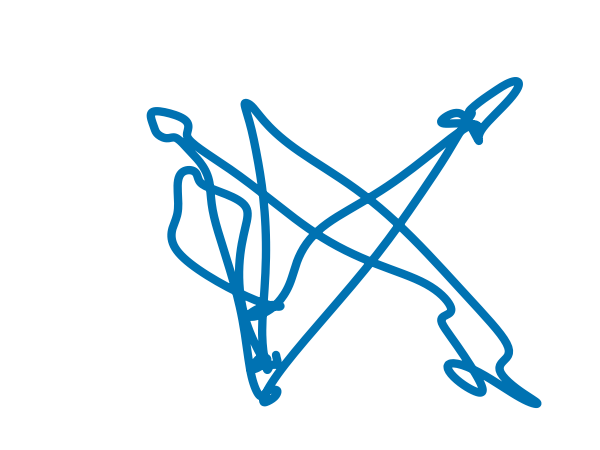

In [12]:
with quiet_hypertools():
    fig, ax = plt.subplots(figsize=(4, 3), facecolor='white', subplot_kw={'projection': '3d'})
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    line, _ = trajectory_panel(ax, features['Human movement'][1], COLORS[0], '', linewidth=4, fontsize=1)
    for artist in list(ax.lines):
        if artist is not line:                                # the box
            artist.remove()
    ax.set_axis_off()
    fill_panel(ax, [-60], fill=1.5, title_px=0)            # the line fills the picture, not the box
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=150, facecolor='white')
    plt.close(fig)
display(PILImage.open(buf))

In [13]:
print(f'notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} min')

notebook run time: 1.4 min
